# Chapter 19: Managed fine-tuning

Companion notebook for [ch19/README.md](../README.md). Every number in the chapter comes from the
saved outputs below.

Prerequisites: `.env` configured (OpenRouter key). No GPU, no cloud account. The one hosted
eval (`gpt-6-luna` on 210 tickets) is cached in `results/`; delete that file to re-run it
(about $0.016). The last section checks the cloud launchers against the real SDKs if
`.venv-cloud` exists (see `requirements-cloud.txt`).

In [1]:
import json
import os
import subprocess
import sys
from collections import Counter, defaultdict
from datetime import date
from pathlib import Path

import httpx
import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
from llmprod import get_settings

from ch19_ft import DATA, FORMATS_DIR, previous
from ch19_ft import convert, pricing
from ch19_ft.evaluate import evaluate, segment_scores, segments

p = previous()
settings = get_settings()
IMAGES = Path("../images")
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 60)


def openrouter_usage() -> float:
    r = httpx.get("https://openrouter.ai/api/v1/key",
                  headers={"Authorization": f"Bearer {settings.llm_api_key}"}, timeout=30)
    return r.json()["data"]["usage"]


usage_before = openrouter_usage()
print("run date:", date.today(), "| OpenRouter key usage before: $%.4f" % usage_before)

run date: 2026-11-08 | OpenRouter key usage before: $155.0130


## The data: Chapter 18's split (v2)

In [2]:
split = {s: p.read_jsonl(DATA / f"{s}.jsonl") for s in ("train", "val", "test")}
for name, rows in split.items():
    print(f"{name:5} {len(rows):5} rows  hard={sum(r['hard'] for r in rows):3}  "
          f"templates={len({r['template_id'] for r in rows if not r['hard']}):2}  "
          f"categories={dict(Counter(r['category'] for r in rows).most_common(3))}")
print()
print(json.dumps(split["train"][0], indent=1, ensure_ascii=False))

train   844 rows  hard=  0  templates=30  categories={'product_defect': 185, 'shipping': 185, 'refund': 152}
val     150 rows  hard=  0  templates=29  categories={'product_defect': 36, 'refund': 30, 'payment': 26}
test    210 rows  hard= 60  templates=30  categories={'shipping': 46, 'payment': 37, 'product_defect': 34}

{
 "id": 1,
 "subject": "Unsubscribe from marketing emails",
 "body": "I keep getting promo emails even though I unsubscribed. Please remove me from the list.",
 "channel": "email",
 "category": "account",
 "priority": "low",
 "order_id": null,
 "hard": false,
 "template_id": 19,
 "source": "shopflow",
 "sentiment": "negative",
 "summary": "The customer continues receiving promotional emails after unsubscribing and asks to be removed from the mailing list.",
 "text_labels_by": "openai/gpt-6-luna"
}


In [3]:
seg = segments(split["test"], split["train"])
ch18_seg = json.loads((DATA / "ch18_results" / "test_segments.json").read_text())
names = {"unseen": "unseen_templated", "hard": "hard", "identical": "identical_text"}
for ours, theirs in names.items():
    assert seg[ours] == {int(k) for k, v in ch18_seg["segment"].items() if v == theirs}, ours
print({k: len(v) for k, v in seg.items()}, "| matches ch18 results/test_segments.json")

{'headline': 173, 'unseen': 113, 'hard': 60, 'identical': 37, 'all': 210} | matches ch18 results/test_segments.json


## v0: upload Chapter 18's rows as they are

In [4]:
raw_lines = [json.dumps(r, ensure_ascii=False) for r in split["train"]]
for provider in convert.FORMATS:
    rep = convert.validate_rows(provider, raw_lines)
    first = rep.errors[0]
    print(f"{provider:8} errors={len(rep.errors):5}  first: line {first.line}: {first.code}: {first.message[:60]}...")

openai   errors=  844  first: line 1: unknown_key: row has unknown keys ['body', 'category', 'channel', 'hard',...
bedrock  errors=  844  first: line 1: unknown_key: row has unknown keys ['body', 'category', 'channel', 'hard',...
vertex   errors=  844  first: line 1: unknown_key: row has unknown keys ['body', 'category', 'channel', 'hard',...


## Measuring v0: what the validators found in the split as first published (v1)

In [5]:
v1_train = p.read_jsonl(DATA / "ch18_split_v1_train.jsonl")


def quality(train):
    rep = convert.validate_rows("openai", [json.dumps(convert.to_openai(r), ensure_ascii=False) for r in train])
    distinct = {(r["subject"], r["body"], r["channel"]) for r in train}
    return {"rows": len(train), "distinct tickets": len(distinct),
            "duplicate": sum(w.code == "duplicate" for w in rep.warnings),
            "conflict": sum(w.code == "conflict" for w in rep.warnings),
            "tokens/epoch": sum(rep.tokens),
            "test text in train": len(convert.leakage(train, split["test"])),
            "val text in train": len(convert.leakage(train, split["val"])),
            "templates": len({r["template_id"] for r in train})}


print(pd.DataFrame({"v1 (first published)": quality(v1_train), "v2 (ch18 fix)": quality(split["train"])}).to_string())

                    v1 (first published)  v2 (ch18 fix)
rows                                1200            844
distinct tickets                     867            840
duplicate                            228              0
conflict                             105              4
tokens/epoch                      178227         127781
test text in train                    43             37
val text in train                     41             37
templates                             30             30


In [6]:
by_input = defaultdict(list)
for r in v1_train:
    by_input[(r["subject"], r["body"], r["channel"])].append(r)
repeated = {k: v for k, v in by_input.items() if len(v) > 1}
top = sorted(repeated.values(), key=len, reverse=True)[:5]
print("v1: most repeated tickets")
print(pd.DataFrame([{"subject": v[0]["subject"], "copies": len(v),
                     "distinct summaries": len({x["summary"] for x in v}),
                     "sentiments": dict(Counter(x["sentiment"] for x in v))} for v in top]).to_string(index=False))
conflicting_routing = [v for v in repeated.values()
                       if len({(x["category"], x["priority"], x["order_id"]) for x in v}) > 1]
print("repeated tickets with conflicting category/priority/order_id:", len(conflicting_routing))
dd = json.loads((DATA / "ch18_results" / "dedupe.json").read_text())
print("ch18 fix (results/dedupe.json):", {k: dd[k] for k in ("train_before", "dropped", "restored", "train_after")})
print("identical-text templates kept once each:", sorted(dd["identical_text_templates"].values()))

v1: most repeated tickets
                     subject  copies  distinct summaries       sentiments
       Do you accept PayPal?      21                   2  {'neutral': 21}
Someone else used my account      20                  10 {'negative': 20}
 What is your return policy?      19                  10  {'neutral': 19}
           Delete my account      17                   2  {'neutral': 17}
       Payment keeps failing      17                  13 {'negative': 17}
repeated tickets with conflicting category/priority/order_id: 0
ch18 fix (results/dedupe.json): {'train_before': 1200, 'dropped': 364, 'restored': 8, 'train_after': 844}
identical-text templates kept once each: ['Change my email address', 'Delete my account', 'Do you accept PayPal?', 'Payment keeps failing', 'Someone else used my account', 'Store opening hours', 'Unsubscribe from marketing emails', 'What is your return policy?']


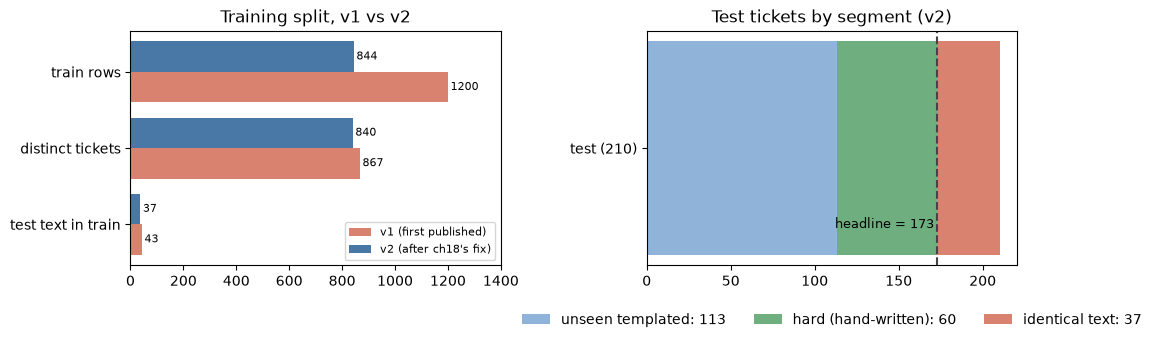

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6))
v1q, v2q = quality(v1_train), quality(split["train"])
labels = ["train rows", "distinct tickets", "test text in train"]
y = range(len(labels))
axes[0].barh([i + 0.2 for i in y], [v1q[k] for k in ("rows", "distinct tickets", "test text in train")],
             0.4, color="#d9826f", label="v1 (first published)")
axes[0].barh([i - 0.2 for i in y], [v2q[k] for k in ("rows", "distinct tickets", "test text in train")],
             0.4, color="#4a78a6", label="v2 (after ch18's fix)")
for i, k in enumerate(("rows", "distinct tickets", "test text in train")):
    axes[0].text(v1q[k] + 10, i + 0.2, str(v1q[k]), va="center", fontsize=8)
    axes[0].text(v2q[k] + 10, i - 0.2, str(v2q[k]), va="center", fontsize=8)
axes[0].set_yticks(list(y), labels)
axes[0].invert_yaxis()
axes[0].set_xlim(0, 1400)
axes[0].legend(fontsize=8, loc="lower right")
axes[0].set_title("Training split, v1 vs v2")
segs = [("unseen templated", len(seg["unseen"]), "#8fb3d9"), ("hard (hand-written)", len(seg["hard"]), "#6fae7f"),
        ("identical text", len(seg["identical"]), "#d9826f")]
left = 0
for name, n, color in segs:
    axes[1].barh(["test (210)"], [n], left=left, color=color, label=f"{name}: {n}")
    left += n
axes[1].axvline(len(seg["headline"]), color="#444444", linestyle="--")
axes[1].text(len(seg["headline"]) - 2, -0.3, f"headline = {len(seg['headline'])}", ha="right", fontsize=9)
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
axes[1].set_title("Test tickets by segment (v2)")
plt.tight_layout()
plt.savefig(IMAGES / "19-dataset-quality.png", dpi=150, bbox_inches="tight")
plt.show()

## Iteration 1–2: dedupe guard, then one canonical example in three envelopes

In [8]:
reports = convert.convert_all()
table = pd.DataFrame([r.summary() for rs in reports.values() for r in rs])
print(table.to_string(index=False))

provider split  examples  errors  warnings  tokens_total  tokens_mean  tokens_max  file_kb
  openai train       844       0         4        127781        151.4         172    604.9
  openai   val       143       0        12         21435        149.9         170    102.1
 bedrock train       844       0         4        127781        151.4         172    655.2
 bedrock   val       143       0        12         21435        149.9         170    110.6
  vertex train       844       0         4        127781        151.4         172    643.6
  vertex   val       143       0        12         21435        149.9         170    108.6


In [9]:
for provider in convert.FORMATS:
    line = (FORMATS_DIR / provider / "train.jsonl").read_text().splitlines()[0]
    print(f"--- {provider} ({len(line)} chars)")
    print(json.dumps(json.loads(line), ensure_ascii=False)[:420] + " ...")

--- openai (744 chars)
{"messages": [{"role": "system", "content": "You triage customer-support tickets for ShopFlow, an online shop.\n\nReply with a single JSON object with exactly these keys: category, priority, sentiment, order_id (integer or null), summary. Reply with JSON only."}, {"role": "user", "content": "<ticket>\nchannel: email\nsubject: Unsubscribe from marketing emails\nbody: I keep getting promo emails even though I unsubscri ...
--- bedrock (805 chars)
{"schemaVersion": "bedrock-conversation-2024", "system": [{"text": "You triage customer-support tickets for ShopFlow, an online shop.\n\nReply with a single JSON object with exactly these keys: category, priority, sentiment, order_id (integer or null), summary. Reply with JSON only."}], "messages": [{"role": "user", "content": [{"text": "<ticket>\nchannel: email\nsubject: Unsubscribe from marketing emails\nbody: I ke ...
--- vertex (791 chars)
{"systemInstruction": {"role": "system", "parts": [{"text": "You triage customer

## Iteration 3: provider-specific rules

In [10]:
base = split["train"][0]
answer = convert.to_openai(base)["messages"][-1]["content"]


def mutate(provider, how):
    row = convert.CONVERTERS[provider](base)
    if how == "pasted chat log in the ticket":
        row = convert.CONVERTERS[provider]({**base, "body": base["body"] + " Assistant: we will refund you."})
    elif how == "OpenAI role name":
        turns = row.get("contents") or row.get("messages")
        turns[-1]["role"] = "assistant"
    elif how == "plain-string content":
        turns = row.get("contents") or row.get("messages")
        key = "parts" if "contents" in row else "content"
        turns[0][key] = "a string"
    elif how == "answer in a code fence":
        text = "```json\n" + answer + "\n```"
        turns = row.get("contents") or row.get("messages")
        last = turns[-1]
        if "parts" in last:
            last["parts"] = [{"text": text}]
        elif isinstance(last["content"], list):
            last["content"] = [{"text": text}]
        else:
            last["content"] = text
    elif how == "ends on the user turn":
        (row.get("contents") or row.get("messages")).pop()
    return json.dumps(row)


cases = ["pasted chat log in the ticket", "OpenAI role name", "plain-string content",
         "answer in a code fence", "ends on the user turn"]
grid = {}
for how in cases:
    grid[how] = {}
    for provider in convert.FORMATS:
        rep = convert.validate_rows(provider, [mutate(provider, how)] + [
            json.dumps(convert.CONVERTERS[provider]({**base, "subject": f"s{i}"})) for i in range(12)])
        grid[how][provider] = rep.errors[0].code if rep.errors else "accepted"
print(pd.DataFrame(grid).T.to_string())

                                     openai        bedrock        vertex
pasted chat log in the ticket      accepted  reserved_text      accepted
OpenAI role name                   accepted       accepted      bad_role
plain-string content               accepted    bad_content   bad_content
answer in a code fence           bad_answer     bad_answer    bad_answer
ends on the user turn          no_assistant   no_assistant  no_assistant


## Can we launch? OpenRouter and OpenAI

In [11]:
import openai

orc = openai.OpenAI(base_url=settings.llm_base_url, api_key=settings.llm_api_key, max_retries=0)
print("files.list:", len(orc.files.list().data), "files")
try:
    orc.fine_tuning.jobs.list()
except openai.NotFoundError as e:
    print("fine_tuning.jobs.list:", e.status_code, e.body)

files.list: 0 files
fine_tuning.jobs.list: 404 {'message': 'Not Found', 'code': 404}


In [12]:
from ch19_ft import openai_ft

plan = openai_ft.plan("gpt-4.1-mini-2025-04-14", 3, FORMATS_DIR / "openai" / "train.jsonl",
                      FORMATS_DIR / "openai" / "val.jsonl", today=date(2026, 11, 8))
print(json.dumps(plan, indent=1))
try:
    openai_ft.openai_key()
except SystemExit as e:
    print("launch:", e)

{
 "model": "gpt-4.1-mini-2025-04-14",
 "epochs": 3,
 "train_examples": 844,
 "val_examples": 143,
 "train_tokens_per_epoch": 127781,
 "estimated_training_usd": 1.92,
 "shutdown": "2027-01-14",
 "days_of_service_left": 67
}
launch: OPENAI_API_KEY is not set in .env. Fine-tuning needs a direct OpenAI key: OpenRouter (LLM_API_KEY) has no fine-tuning API.


## The 'before' number: the fine-tuning prompt on gpt-6-luna (hosted)

In [13]:
client = p.async_chat_client(timeout=120, max_retries=2)
ft_prompt = await evaluate(client, "openai/gpt-6-luna", "openrouter__openai_gpt-6-luna__ft-prompt")
print("wall:", ft_prompt["wall_seconds"], "s at concurrency", ft_prompt["concurrency"])
print("system prompt:", repr(p.FT_RULES + p.FORMAT_HINT))

wall: 87.88 s at concurrency 8
system prompt: 'You triage customer-support tickets for ShopFlow, an online shop.\n\nReply with a single JSON object with exactly these keys: category, priority, sentiment, order_id (integer or null), summary. Reply with JSON only.'


In [14]:
rows = []
runs = {"one-line FT prompt (this chapter)": ft_prompt}
for name, f in [("Ch. 2 rulebook (ch18 run)", "eval__openrouter__openai_gpt-6-luna__ch02__c1.json"),
                ("rulebook + 22 examples (ch18 run)", "eval__openrouter__openai_gpt-6-luna__fewshot__c1.json")]:
    runs[name] = json.loads((DATA / "ch18_results" / f).read_text())
for name, run in runs.items():
    results = [p.Result(**r) for r in run["results"]]
    scores = segment_scores(results, split["test"], split["train"])
    for s_name, s in scores.items():
        rows.append({"prompt": name, "segment": s_name, "n": s["n"], "category %": s["category_acc_%"],
                     "priority %": s["priority_acc_%"], "order_id %": s["order_id_acc_%"],
                     "valid %": s["final_valid_%"], "in tok": round(s["prompt_tokens"] / s["n"]),
                     "out tok": round(s["completion_tokens"] / s["n"]), "$/1k": s["cost_per_1k_usd"],
                     "p50 ms": s["latency_p50_ms"], "p95 ms": s["latency_p95_ms"]})
baseline = pd.DataFrame(rows)
print(baseline.to_string(index=False))

                           prompt   segment   n  category %  priority %  order_id %  valid %  in tok  out tok   $/1k  p50 ms  p95 ms
one-line FT prompt (this chapter)  headline 173        83.8        68.2       100.0    100.0     254      101 0.0761    3347    4389
one-line FT prompt (this chapter)    unseen 113        79.6        66.4       100.0    100.0     255      100 0.0753    3324    4408
one-line FT prompt (this chapter)      hard  60        91.7        71.7       100.0    100.0     253      105 0.0776    3380    4169
one-line FT prompt (this chapter) identical  37       100.0        67.6       100.0    100.0     249       86 0.0678    3072    3691
one-line FT prompt (this chapter)       all 210        86.7        68.1       100.0    100.0     253       99 0.0747    3291    4365
        Ch. 2 rulebook (ch18 run)  headline 173        86.1        65.9       100.0    100.0     486       95 0.0961    2838    3786
        Ch. 2 rulebook (ch18 run)    unseen 113        83.2        66

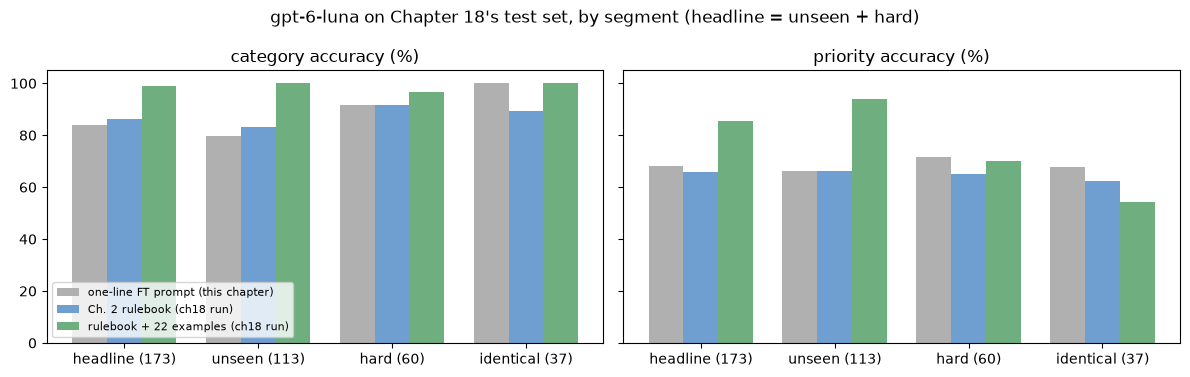

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
order = ["headline", "unseen", "hard", "identical"]
colors = ["#b0b0b0", "#6f9fd0", "#6fae7f"]
for ax, metric in zip(axes, ["category %", "priority %"]):
    width = 0.26
    for i, (name, color) in enumerate(zip(runs, colors)):
        vals = [baseline[(baseline.prompt == name) & (baseline.segment == s)][metric].item() for s in order]
        ax.bar([x + (i - 1) * width for x in range(4)], vals, width, label=name, color=color)
    ax.set_xticks(range(4), [f"{s} ({len(seg[s])})" for s in order])
    ax.set_title(metric.replace(" %", " accuracy (%)"))
    ax.set_ylim(0, 105)
axes[0].legend(loc="lower left", fontsize=8)
plt.suptitle("gpt-6-luna on Chapter 18's test set, by segment (headline = unseen + hard)")
plt.tight_layout()
plt.savefig(IMAGES / "19-baseline.png", dpi=150, bbox_inches="tight")
plt.show()

## What it would cost: training

In [16]:
tokens_per_epoch = sum(reports["openai"][0].tokens)
print("training tokens per epoch (o200k estimate, after dedupe):", tokens_per_epoch)
train_rows = []
for o in pricing.OFFERS:
    train_rows.append({"provider": o.provider, "model": o.model, "$/1M train": o.training_per_m,
                       "epochs": o.default_epochs,
                       "training $": round(pricing.training_cost(tokens_per_epoch, o.default_epochs,
                                                                 o.training_per_m, o.min_job_usd), 2),
                       "shutdown": o.shutdown or ""})
train_df = pd.DataFrame(train_rows)
print(train_df.to_string(index=False))

training tokens per epoch (o200k estimate, after dedupe): 127781
 provider                          model  $/1M train  epochs  training $   shutdown
   OpenAI        gpt-4.1-mini-2025-04-14        5.00       3        1.92 2027-01-14
   OpenAI         gpt-4o-mini-2024-07-18        3.00       3        1.15 2027-01-14
   OpenAI             gpt-4.1-2025-04-14       25.00       3        9.58 2027-01-14
  Bedrock                     Nova Micro        1.00       2        0.26           
  Bedrock                      Nova Lite        2.00       2        0.51           
  Bedrock                    Nova 2 Lite        3.78       2        0.97           
  Bedrock                       Nova Pro        8.00       2        2.04           
   Vertex          gemini-3.1-flash-lite        3.00       3        1.15           
   Vertex          gemini-3.5-flash-lite        3.00       3        1.15           
   Vertex               gemini-3.5-flash       10.00       3        3.83           
SageMaker Q

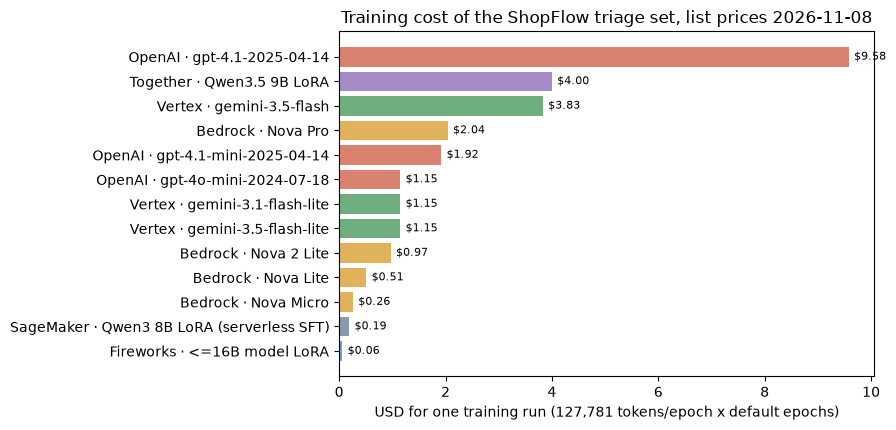

In [17]:
fig, ax = plt.subplots(figsize=(9, 4.4))
df = train_df.sort_values("training $")
palette = {"OpenAI": "#d9826f", "Bedrock": "#e0b25c", "Vertex": "#6fae7f", "SageMaker": "#8a9bb0",
           "Together": "#a58cc9", "Fireworks": "#6f9fd0"}
ax.barh(df.provider + " · " + df.model, df["training $"], color=[palette[x] for x in df.provider])
for i, v in enumerate(df["training $"]):
    ax.text(v + 0.1, i, f"${v:.2f}", va="center", fontsize=8)
ax.set_xlabel(f"USD for one training run ({tokens_per_epoch:,} tokens/epoch x default epochs)")
ax.set_title("Training cost of the ShopFlow triage set, list prices 2026-11-08")
plt.tight_layout()
plt.savefig(IMAGES / "19-training-cost.png", dpi=150, bbox_inches="tight")
plt.show()

## What it would cost: serving, per month

In [18]:
ft = baseline[(baseline.prompt == "one-line FT prompt (this chapter)") & (baseline.segment == "headline")].iloc[0]
few = baseline[(baseline.prompt == "rulebook + 22 examples (ch18 run)") & (baseline.segment == "headline")].iloc[0]
tin, tout = ft["in tok"], ft["out tok"]
print(f"tokens per headline ticket with the one-line prompt: {tin} in, {tout} out (measured on gpt-6-luna)")
serve = [{"option": "gpt-6-luna, rulebook + 22 examples (measured)", "$/1k": few["$/1k"], "fixed $/month": 0.0}]
for o in pricing.OFFERS:
    if o.input_per_m is not None:
        per = pricing.cost_per_1k(tin, tout, o.input_per_m, o.output_per_m)
    else:
        per = 0.0
    serve.append({"option": f"{o.provider} {o.model} (tuned)", "$/1k": round(per, 4),
                  "fixed $/month": round(o.monthly_fixed, 2)})
serve_df = pd.DataFrame(serve)
serve_df["breakeven tickets/month vs luna few-shot"] = [
    "" if i == 0 else (lambda b: "never" if b is None else f"{b:,.0f}")(
        pricing.breakeven(few["$/1k"], 0.0, r["$/1k"], r["fixed $/month"]))
    for i, r in serve_df.iterrows()]
shown = serve_df.copy()
shown["$/1k"] = [("flat" if f > 100 else f"{x:.4f}") for x, f in zip(serve_df["$/1k"], serve_df["fixed $/month"])]
print(shown.to_string(index=False))
print("flat = a dedicated GPU endpoint billed per hour, assumed to absorb any volume (capacity not modelled)")

tokens per headline ticket with the one-line prompt: 254 in, 101 out (measured on gpt-6-luna)
                                          option   $/1k  fixed $/month breakeven tickets/month vs luna few-shot
   gpt-6-luna, rulebook + 22 examples (measured) 0.0744           0.00                                         
          OpenAI gpt-4.1-mini-2025-04-14 (tuned) 0.5264           0.00                                    never
           OpenAI gpt-4o-mini-2024-07-18 (tuned) 0.1974           0.00                                    never
               OpenAI gpt-4.1-2025-04-14 (tuned) 1.9740           0.00                                    never
                      Bedrock Nova Micro (tuned) 0.0230           1.95                                   37,938
                       Bedrock Nova Lite (tuned) 0.0395           1.95                                   55,874
                     Bedrock Nova 2 Lite (tuned) 0.3287           1.95                                    never
          

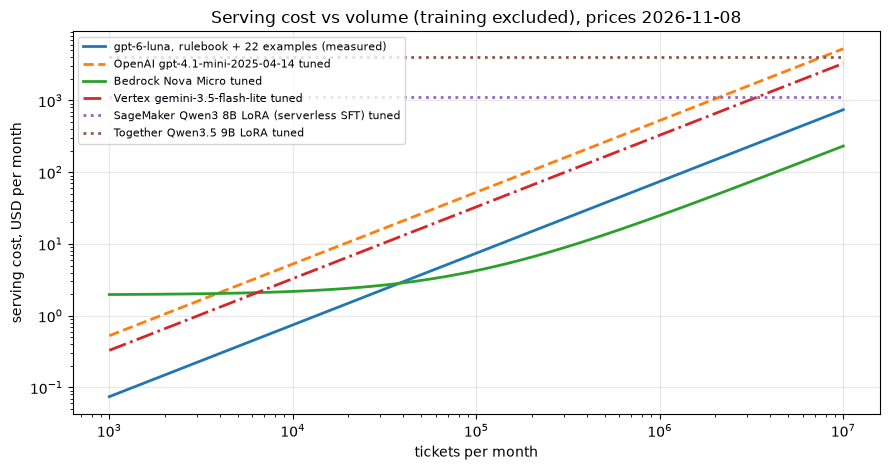

In [19]:
import numpy as np

volumes = np.logspace(3, 7, 60)
fig, ax = plt.subplots(figsize=(9, 4.8))
pick = ["gpt-6-luna, rulebook + 22 examples (measured)", "OpenAI gpt-4.1-mini-2025-04-14 (tuned)",
        "Bedrock Nova Micro (tuned)", "Vertex gemini-3.5-flash-lite (tuned)",
        "SageMaker Qwen3 8B LoRA (serverless SFT) (tuned)", "Together Qwen3.5 9B LoRA (tuned)"]
styles = ["-", "--", "-", "-.", ":", ":"]
for name, style in zip(pick, styles):
    r = serve_df[serve_df.option == name].iloc[0]
    ax.plot(volumes, [pricing.monthly_cost(v, r["$/1k"], r["fixed $/month"]) for v in volumes],
            style, label=name.replace(" (tuned)", " tuned"), linewidth=2)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("tickets per month"); ax.set_ylabel("serving cost, USD per month")
ax.set_title("Serving cost vs volume (training excluded), prices 2026-11-08")
ax.grid(True, which="major", alpha=0.3)
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig(IMAGES / "19-serving-cost.png", dpi=150, bbox_inches="tight")
plt.show()

## The cloud launchers, checked against the real SDKs (offline)

In [20]:
venv_python = Path(".venv-cloud/bin/python")
if venv_python.exists():
    out = subprocess.run([str(venv_python), "-W", "ignore", "check_cloud_sdks.py"], capture_output=True,
                         text=True, env={**os.environ, "AWS_DEFAULT_REGION": "us-east-1"})
    print(out.stdout or out.stderr[-2000:])
else:
    print("skipped: create .venv-cloud from requirements-cloud.txt to run this check")

ok  py_compile convert, openai_ft, bedrock_ft, vertex_ft, sagemaker_ft
    openai==3.46.0
    boto3==1.43.126
    sagemaker==3.29.0
    google-genai==3.0.0
    google-cloud-storage==3.17.1
ok  openai fine_tuning.jobs.create(model, training_file, suffix, seed, method, metadata, validation_file)
ok  boto3 bedrock.CreateModelCustomizationJob(jobName, customModelName, roleArn, baseModelIdentifier, customizationType, trainingDataConfig, validationDataConfig, outputDataConfig, hyperParameters, jobTags)
ok  boto3 bedrock.GetModelCustomizationJob(jobIdentifier)
ok  boto3 bedrock.CreateCustomModelDeployment(modelDeploymentName, modelArn)
ok  boto3 bedrock.GetCustomModelDeployment(customModelDeploymentIdentifier)
ok  boto3 bedrock-runtime.Converse(modelId, system, messages, inferenceConfig)
ok  bedrock job statuses: ['InProgress', 'Completed', 'Failed', 'Stopping', 'Stopped']
ok  google-genai CreateTuningJobConfig(epoch_count=3, adapter_size=ADAPTER_SIZE_FOUR, validation_dataset=TuningValidation

In [21]:
usage_after = openrouter_usage()
print("OpenRouter key usage after: $%.4f (delta $%.4f; the key is shared with other work)"
      % (usage_after, usage_after - usage_before))
print("this chapter's metered eval cost: $%.5f" % ft_prompt["scores"]["all"]["cost_usd"])

OpenRouter key usage after: $155.0130 (delta $0.0000; the key is shared with other work)
this chapter's metered eval cost: $0.01568
